### Лабораторная работа №6. Методы автоматической кластеризации данных
**Цель работы: Практическое освоение алгоритмов обучения без учителя (Unsupervised Learning) на задаче кластеризации, изучение геометрических и плотностных подходов к группировке данных, освоение метрик валидации кластеров, а также интерактивный анализ структуры признакового пространства.**

Часть 1. Работа с наборами данных
Подбор датасетов:    
Для выполнения работы необходимо использовать **два различных набора данных**:
Разрешается использовать очищенные структуры данных из предыдущих лабораторных работ (убрав целевую переменную разметки).   
Либо подобрать новые.   
Предобработка: Провести обязательное масштабирование признаков **(StandardScaler или MinMaxScaler)**, так как большинство алгоритмов кластеризации критичны к метрике расстояния. При необходимости применить методы снижения размерности (например, PCA) для визуализации многомерных пространств на плоскости.


In [1]:
import os
import warnings

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.cluster.hierarchy as sch
import seaborn as sns
from scipy.spatial.distance import pdist
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

RANDOM_SEED = 42

**Соглашение об именах:** переменные с суффиксом `1` относятся к Датасету 1 (Pima Indians Diabetes), с суффиксом `2` — к Датасету 2 (Bank Customer Churn).

### Датасет №1. Pima Indians Diabetes

* **Бизнес-задача:** определить, есть ли у пациента диабет.
* **Объект:** пациент.
* **Признаки:** медицинские показатели (глюкоза, давление, инсулин, BMI, возраст и др.).
* **Целевая переменная:** наличие диабета (`0` — нет, `1` — есть).

In [2]:
path1 = kagglehub.dataset_download("salihacur/diabetes")

csv_file1 = [f for f in os.listdir(path1) if f.endswith('.csv')][0]
df1 = pd.read_csv(os.path.join(path1, csv_file1))

print("Первые 5 строк датасета")
display(df1.head())

print("\nИнформация о типах и пропусках")
df1.info()

(df1 == 0).sum()

Первые 5 строк датасета


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Информация о типах и пропусках
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.2 KB


Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [3]:
# Датасет 1 (Pima Diabetes): целевой столбец исключается из признаков
target1 = 'Outcome'

# В этих признаках 0 означает пропуск
zero_missing1 = {'glucose', 'bloodpressure', 'skinthickness', 'insulin', 'bmi'}
cols1 = [c for c in df1.columns if c.lower() in zero_missing1]
df1[cols1] = df1[cols1].replace(0, np.nan)

x_1 = df1.drop(columns=target1)
y_1 = df1[target1]

imputer1 = SimpleImputer(strategy='median')
x_1 = imputer1.fit_transform(x_1)

scaler1 = StandardScaler()
x_1 = scaler1.fit_transform(x_1)

pca1 = PCA(n_components=2)
x1_pca = pca1.fit_transform(x_1)

display(df1.head())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


### Датасет №2. Bank Customer Churn

* **Бизнес-задача:** определить, уйдёт ли клиент из банка.
* **Объект:** клиент банка.
* **Признаки:** кредитный рейтинг, страна, пол, возраст, стаж, баланс, число продуктов и др.
* **Целевая переменная:** `Exited` (`0` — клиент остался, `1` — ушёл).

In [4]:
path2 = kagglehub.dataset_download("shrutimechlearn/churn-modelling")

csv_file2 = [f for f in os.listdir(path2) if f.endswith('.csv')][0]
df2 = pd.read_csv(os.path.join(path2, csv_file2))

print("Первые 5 строк датасета")
display(df2.head())

print("\nИнформация о типах и пропусках")
df2.info()

Первые 5 строк датасета


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Информация о типах и пропусках
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [5]:
# Датасет 2 (Churn): удаляем идентификаторы, кодируем категориальные признаки
df2 = df2.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
df2 = pd.get_dummies(df2, columns=['Geography', 'Gender'], drop_first=True, dtype=int)

x_2 = df2.drop(columns='Exited')
y_2 = df2['Exited']

scaler2 = StandardScaler()
x_2 = scaler2.fit_transform(x_2)

pca2 = PCA(n_components=2)
x2_pca = pca2.fit_transform(x_2)

display(df2.head())

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


Часть 2. Программа моделирования и визуализации
1. Реализация алгоритмов кластеризации   
Реализовать на выбранных данных три различных алгоритма кластеризации, основанных на принципиально разных математических подходах:   
* Разделяющий (метрический) подход: Алгоритм k-средних (K-Means).   
* Плотностной подход: Алгоритм DBSCAN (или HDBSCAN).   
* Иерархический подход: Агломеративная иерархическая кластеризация (Agglomerative Clustering).   
3. Настройка и поиск параметров
Для алгоритма K-Means обосновать выбор количества кластеров с помощью метода «локтя» (Elbow Method).
Для алгоритма DBSCAN выполнить базовую настройку радиуса окрестности (eps) и минимального количества точек (min_samples).
4. Визуализация результатов
Построить двухмерные диаграммы рассеяния (scatterplot) для каждого алгоритма, где точки окрашены в соответствии с присвоенными метками кластеров.
Для алгоритма иерархической кластеризации построить дендрограмму для визуализации процесса объединения объектов.

## Дендрограммы
Необязательное задание, однако в нем лучше видно значение K для обоих датасетов

#### Датасет 1 (Pima Indians Diabetes)

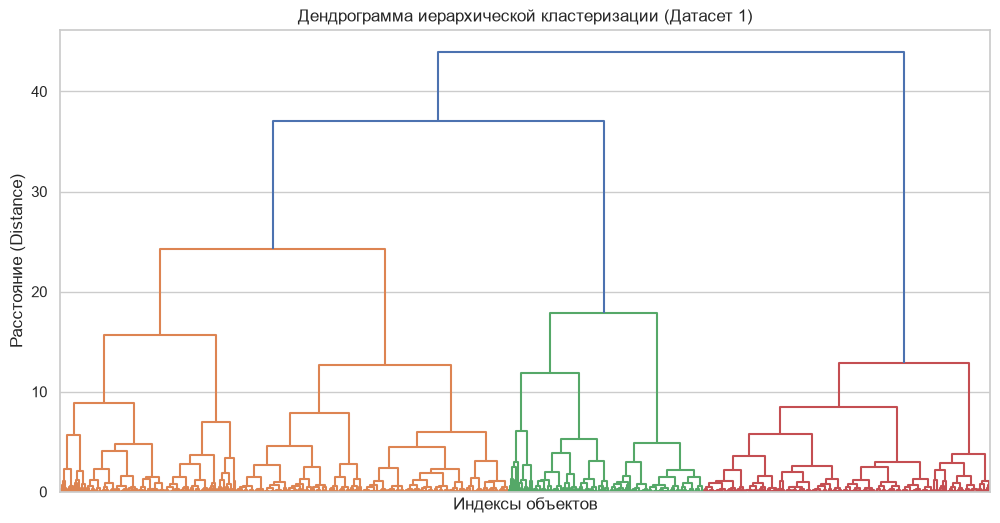

In [6]:
# Датасет 1 (Pima Diabetes): метод Уорда минимизирует дисперсию внутри кластеров
plt.figure(figsize=(12, 6))
plt.title('Дендрограмма иерархической кластеризации (Датасет 1)')
plt.xlabel('Индексы объектов')
plt.ylabel('Расстояние (Distance)')

linked1 = sch.linkage(x1_pca, method='ward')
sch.dendrogram(linked1,
               orientation='top',
               distance_sort='descending',
               show_leaf_counts=True,
               no_labels=True)

plt.show()

#### Датасет 2 (Bank Customer Churn)

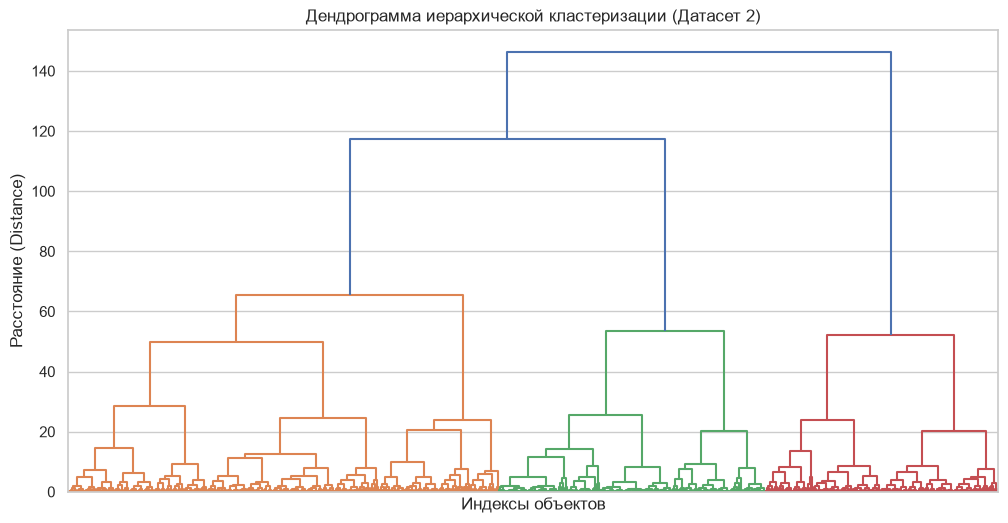

In [7]:
# Датасет 2 (Churn): метод Уорда минимизирует дисперсию внутри кластеров
plt.figure(figsize=(12, 6))
plt.title('Дендрограмма иерархической кластеризации (Датасет 2)')
plt.xlabel('Индексы объектов')
plt.ylabel('Расстояние (Distance)')

linked2 = sch.linkage(x2_pca, method='ward')
sch.dendrogram(linked2,
               orientation='top',
               distance_sort='descending',
               show_leaf_counts=True,
               no_labels=True)

plt.show()

### Разделяющий (метрический) подход: Алгоритм k-средних (K-Means).   

#### Датасет 1 (Pima Indians Diabetes)

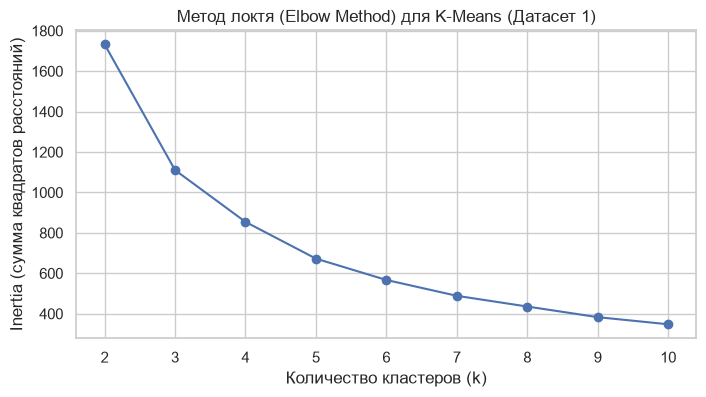

In [8]:
# Датасет 1 (Pima Diabetes): метод локтя
k_range1 = range(2, 11)
inertia1 = []

for k in k_range1:
    km = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10)
    km.fit(x1_pca)
    inertia1.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range1, inertia1, marker='o')
plt.title('Метод локтя (Elbow Method) для K-Means (Датасет 1)')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Inertia (сумма квадратов расстояний)')
plt.grid(True)
plt.show()

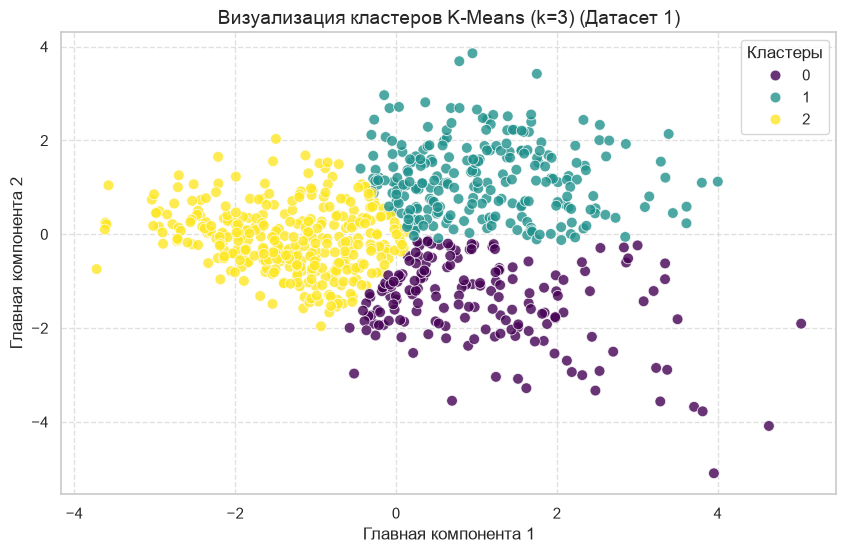

In [9]:
# Датасет 1 (Pima Diabetes): K-Means с выбранным k
optimal_k1 = 3
kmeans_final1 = KMeans(n_clusters=optimal_k1, random_state=RANDOM_SEED, n_init=10)
kmeans_labels1 = kmeans_final1.fit_predict(x1_pca)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=x1_pca[:, 0],
    y=x1_pca[:, 1],
    hue=kmeans_labels1,
    palette='viridis',
    s=60,
    alpha=0.8,
    edgecolor='w'
)

plt.title(f'Визуализация кластеров K-Means (k={optimal_k1}) (Датасет 1)', fontsize=14)
plt.xlabel('Главная компонента 1', fontsize=12)
plt.ylabel('Главная компонента 2', fontsize=12)
plt.legend(title='Кластеры')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

#### Датасет 2 (Bank Customer Churn)

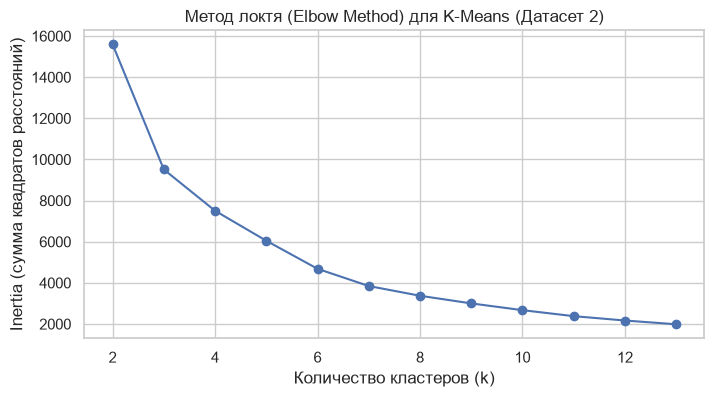

In [10]:
# Датасет 2 (Churn): метод локтя
k_range2 = range(2, 14)
inertia2 = []

for k in k_range2:
    km = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10)
    km.fit(x2_pca)
    inertia2.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range2, inertia2, marker='o')
plt.title('Метод локтя (Elbow Method) для K-Means (Датасет 2)')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Inertia (сумма квадратов расстояний)')
plt.grid(True)
plt.show()

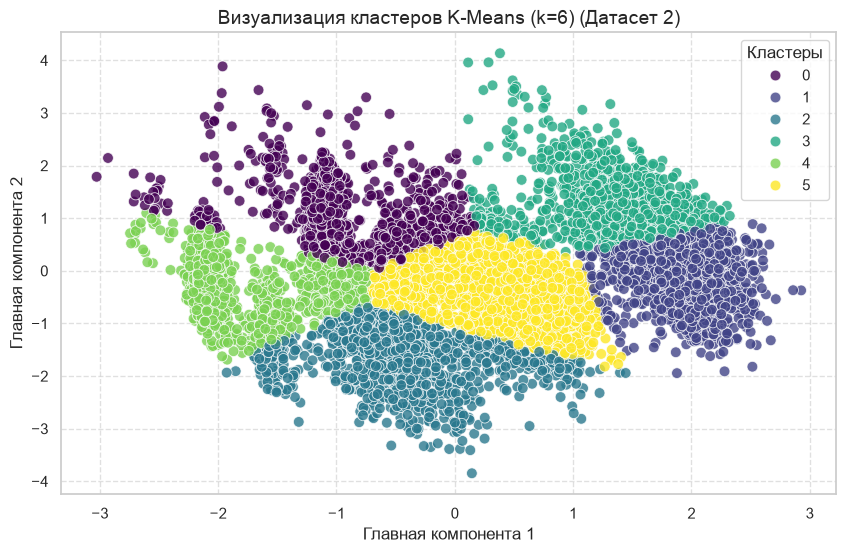

In [11]:
# Датасет 2 (Churn): K-Means с выбранным k
optimal_k2 = 6
kmeans_final2 = KMeans(n_clusters=optimal_k2, random_state=RANDOM_SEED, n_init=10)
kmeans_labels2 = kmeans_final2.fit_predict(x2_pca)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=x2_pca[:, 0],
    y=x2_pca[:, 1],
    hue=kmeans_labels2,
    palette='viridis',
    s=60,
    alpha=0.8,
    edgecolor='w'
)

plt.title(f'Визуализация кластеров K-Means (k={optimal_k2}) (Датасет 2)', fontsize=14)
plt.xlabel('Главная компонента 1', fontsize=12)
plt.ylabel('Главная компонента 2', fontsize=12)
plt.legend(title='Кластеры')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Плотностной подход: Алгоритм DBSCAN (или HDBSCAN).   

#### Датасет 1 (Pima Indians Diabetes)

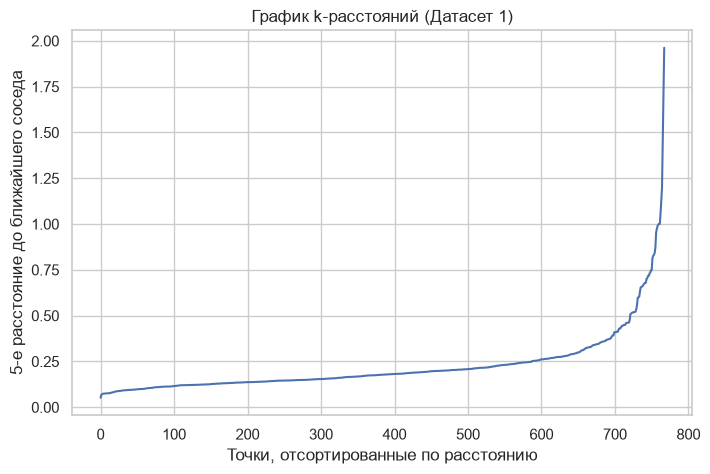

In [12]:
# Датасет 1 (Pima Diabetes): график k-расстояний для подбора eps
min_samples_val1 = 5

neighbors1 = NearestNeighbors(n_neighbors=min_samples_val1).fit(x1_pca)
distances1, _ = neighbors1.kneighbors(x1_pca)

# Расстояние до k-го соседа (k = min_samples; сама точка считается первым соседом)
k_distances1 = np.sort(distances1[:, min_samples_val1 - 1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances1)
plt.title('График k-расстояний (Датасет 1)')
plt.xlabel('Точки, отсортированные по расстоянию')
plt.ylabel(f'{min_samples_val1}-е расстояние до ближайшего соседа')
plt.grid(True)
plt.show()

[Датасет 1] Кластеров: 1, Шумовых точек: 39


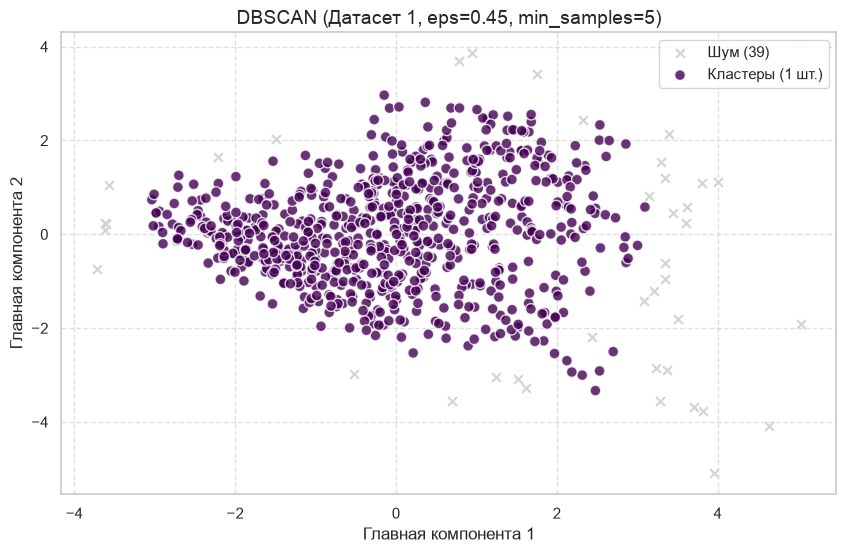

In [13]:
# Датасет 1 (Pima Diabetes): eps выбран по перегибу графика k-расстояний
eps_val1 = 0.45

dbscan1 = DBSCAN(eps=eps_val1, min_samples=min_samples_val1)
dbscan_labels1 = dbscan1.fit_predict(x1_pca)

n_clusters1 = len(set(dbscan_labels1)) - (1 if -1 in dbscan_labels1 else 0)
n_noise1 = list(dbscan_labels1).count(-1)

print(f"[Датасет 1] Кластеров: {n_clusters1}, Шумовых точек: {n_noise1}")

plt.figure(figsize=(10, 6))

noise_mask1 = dbscan_labels1 == -1
plt.scatter(
    x1_pca[noise_mask1, 0], x1_pca[noise_mask1, 1],
    c='lightgray', s=40, marker='x', label=f'Шум ({n_noise1})'
)

cluster_mask1 = dbscan_labels1 != -1
if n_clusters1 > 0:
    plt.scatter(
        x1_pca[cluster_mask1, 0], x1_pca[cluster_mask1, 1],
        c=dbscan_labels1[cluster_mask1], cmap='viridis',
        s=60, alpha=0.8, edgecolor='w', label=f'Кластеры ({n_clusters1} шт.)'
    )

plt.title(f'DBSCAN (Датасет 1, eps={eps_val1}, min_samples={min_samples_val1})', fontsize=14)
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

#### Датасет 2 (Bank Customer Churn)

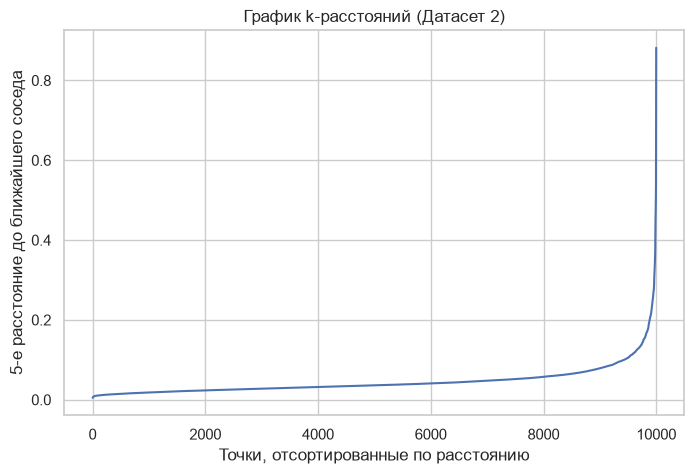

In [14]:
# Датасет 2 (Churn): график k-расстояний для подбора eps
min_samples_val2 = 5

neighbors2 = NearestNeighbors(n_neighbors=min_samples_val2).fit(x2_pca)
distances2, _ = neighbors2.kneighbors(x2_pca)

# Расстояние до k-го соседа (k = min_samples; сама точка считается первым соседом)
k_distances2 = np.sort(distances2[:, min_samples_val2 - 1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances2)
plt.title('График k-расстояний (Датасет 2)')
plt.xlabel('Точки, отсортированные по расстоянию')
plt.ylabel(f'{min_samples_val2}-е расстояние до ближайшего соседа')
plt.grid(True)
plt.show()

[Датасет 2] Кластеров: 4, Шумовых точек: 63


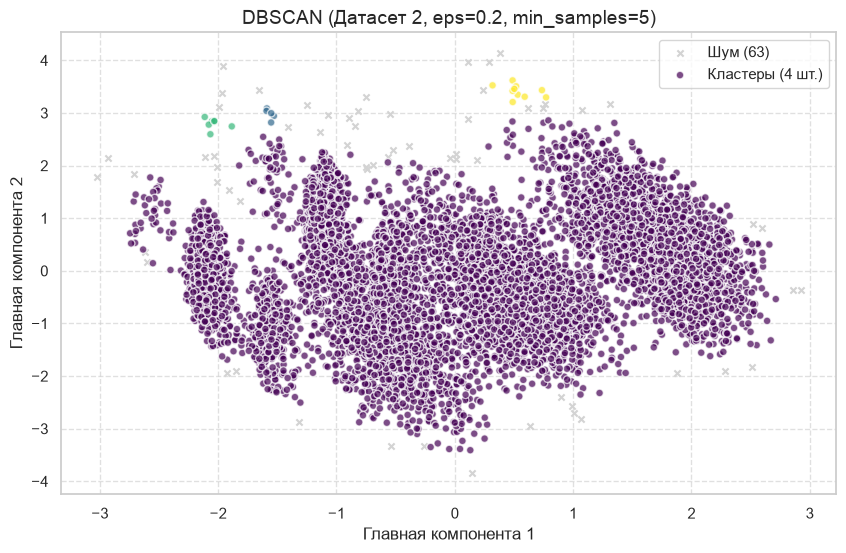

In [15]:
# Датасет 2 (Churn): eps выбран по перегибу графика k-расстояний
eps_val2 = 0.2

dbscan2 = DBSCAN(eps=eps_val2, min_samples=min_samples_val2)
dbscan_labels2 = dbscan2.fit_predict(x2_pca)

n_clusters2 = len(set(dbscan_labels2)) - (1 if -1 in dbscan_labels2 else 0)
n_noise2 = list(dbscan_labels2).count(-1)

print(f"[Датасет 2] Кластеров: {n_clusters2}, Шумовых точек: {n_noise2}")

plt.figure(figsize=(10, 6))

noise_mask2 = dbscan_labels2 == -1
plt.scatter(
    x2_pca[noise_mask2, 0], x2_pca[noise_mask2, 1],
    c='lightgray', s=20, marker='x', label=f'Шум ({n_noise2})'
)

cluster_mask2 = dbscan_labels2 != -1
if n_clusters2 > 0:
    plt.scatter(
        x2_pca[cluster_mask2, 0], x2_pca[cluster_mask2, 1],
        c=dbscan_labels2[cluster_mask2], cmap='viridis',
        s=30, alpha=0.7, edgecolor='w', label=f'Кластеры ({n_clusters2} шт.)'
    )

plt.title(f'DBSCAN (Датасет 2, eps={eps_val2}, min_samples={min_samples_val2})', fontsize=14)
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Иерархический подход: Агломеративная иерархическая кластеризация (Agglomerative Clustering).

#### Датасет 1 (Pima Indians Diabetes)

In [16]:
# Датасет 1 (Pima Diabetes): то же k, что и в K-Means
agg_k1 = 3

agg_model1 = AgglomerativeClustering(n_clusters=agg_k1, linkage='ward')
agg_labels1 = agg_model1.fit_predict(x1_pca)

print(f"[Датасет 1] Уникальные метки кластеров: {set(agg_labels1)}")

[Датасет 1] Уникальные метки кластеров: {np.int64(0), np.int64(1), np.int64(2)}


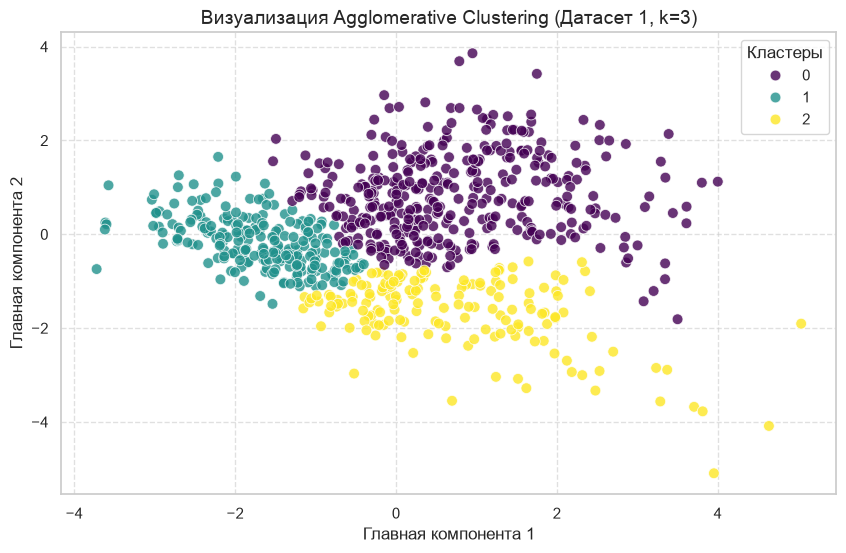

In [17]:
# Датасет 1 (Pima Diabetes)
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=x1_pca[:, 0],
    y=x1_pca[:, 1],
    hue=agg_labels1,
    palette='viridis',
    s=60,
    alpha=0.8,
    edgecolor='w'
)

plt.title(f'Визуализация Agglomerative Clustering (Датасет 1, k={agg_k1})', fontsize=14)
plt.xlabel('Главная компонента 1', fontsize=12)
plt.ylabel('Главная компонента 2', fontsize=12)
plt.legend(title='Кластеры')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

#### Датасет 2 (Bank Customer Churn)

In [18]:
# Датасет 2 (Churn): то же k, что и в K-Means (по методу локтя)
agg_k2 = 6

agg_model2 = AgglomerativeClustering(n_clusters=agg_k2, linkage='ward')
agg_labels2 = agg_model2.fit_predict(x2_pca)

print(f"[Датасет 2] Уникальные метки кластеров: {set(agg_labels2)}")

[Датасет 2] Уникальные метки кластеров: {np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)}


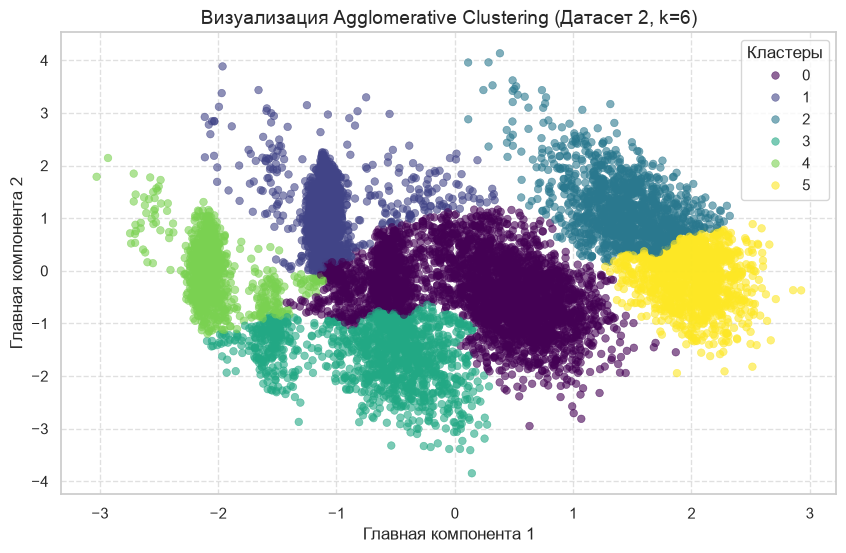

In [19]:
# Датасет 2 (Churn): точек много, поэтому маркеры мельче и без обводки
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=x2_pca[:, 0],
    y=x2_pca[:, 1],
    hue=agg_labels2,
    palette='viridis',
    s=30,
    alpha=0.6,
    edgecolor=None
)

plt.title(f'Визуализация Agglomerative Clustering (Датасет 2, k={agg_k2})', fontsize=14)
plt.xlabel('Главная компонента 1', fontsize=12)
plt.ylabel('Главная компонента 2', fontsize=12)
plt.legend(title='Кластеры')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Часть 3. Оценка качества кластеризации (Валидация)   
Поскольку истинная разметка данных в задаче обучения без учителя отсутствует, необходимо рассчитать внутренние метрики качества для каждого алгоритма:
Вычислить внутрикластерное расстояние (для K-Means — метрика Inertia / сумма квадратов расстояний до центроидов).
Оценить межкластерное расстояние (метрика расстояния между центрами кластеров).
Рассчитать средний коэффициент силуэта (Silhouette Score) для оценки плотности и обособленности полученных групп.
Свести все метрики по трем алгоритмам в общую сравнительную таблицу (pandas.DataFrame) для каждого датасета.


In [20]:
def get_silhouette_safe(X, labels):
    """Silhouette Score без шумовых точек (-1); NaN, если кластеров меньше двух."""
    mask = labels != -1
    if len(set(labels[mask])) > 1:
        return silhouette_score(X[mask], labels[mask])
    return np.nan


# Датасет 1 (Pima Diabetes)
kmeans_inertia1 = kmeans_final1.inertia_
kmeans_inter_dist1 = np.mean(pdist(kmeans_final1.cluster_centers_))  # среднее расстояние между центроидами
kmeans_sil1 = silhouette_score(x1_pca, kmeans_labels1)
dbscan_sil1 = get_silhouette_safe(x1_pca, dbscan_labels1)
agg_sil1 = silhouette_score(x1_pca, agg_labels1)

metrics_df1 = pd.DataFrame({
    'Алгоритм': ['K-Means', 'DBSCAN', 'Agglomerative'],
    'Внутрикластерное (Inertia)': [round(kmeans_inertia1, 2), np.nan, np.nan],
    'Межкластерное (среднее)': [round(kmeans_inter_dist1, 2), np.nan, np.nan],
    'Silhouette Score': [round(kmeans_sil1, 3), round(dbscan_sil1, 3), round(agg_sil1, 3)]
})

In [21]:
# Датасет 2 (Churn)
kmeans_inertia2 = kmeans_final2.inertia_
kmeans_inter_dist2 = np.mean(pdist(kmeans_final2.cluster_centers_))  # среднее расстояние между центроидами
kmeans_sil2 = silhouette_score(x2_pca, kmeans_labels2)
dbscan_sil2 = get_silhouette_safe(x2_pca, dbscan_labels2)
agg_sil2 = silhouette_score(x2_pca, agg_labels2)

metrics_df2 = pd.DataFrame({
    'Алгоритм': ['K-Means', 'DBSCAN', 'Agglomerative'],
    'Внутрикластерное (Inertia)': [round(kmeans_inertia2, 2), np.nan, np.nan],
    'Межкластерное (среднее)': [round(kmeans_inter_dist2, 2), np.nan, np.nan],
    'Silhouette Score': [round(kmeans_sil2, 3), round(dbscan_sil2, 3), round(agg_sil2, 3)]
})

In [22]:
metrics_df1.insert(0, 'Датасет', 'Датасет 1')
metrics_df2.insert(0, 'Датасет', 'Датасет 2')

final_metrics_table = pd.concat([metrics_df1, metrics_df2], ignore_index=True)

print("=== СВОДНАЯ ТАБЛИЦА МЕТРИК ПО ДВУМ ДАТАСЕТАМ ===")
display(final_metrics_table)

=== СВОДНАЯ ТАБЛИЦА МЕТРИК ПО ДВУМ ДАТАСЕТАМ ===


,Датасет,Алгоритм,Внутрикластерное (Inertia),Межкластерное (среднее),Silhouette Score
0,Датасет 1,K-Means,1110.76,2.68,0.409
1,Датасет 1,DBSCAN,NaN,NaN,NaN
2,Датасет 1,Agglomerative,NaN,NaN,0.367
3,Датасет 2,K-Means,4683.91,2.39,0.416
4,Датасет 2,DBSCAN,NaN,NaN,0.297
5,Датасет 2,Agglomerative,NaN,NaN,0.382


### Выводы по сводной таблице

**Датасеты:** Датасет 1 — Pima Indians Diabetes (768 пациентов), Датасет 2 — Bank Customer Churn (10 000 клиентов). Все метрики посчитаны на двумерной проекции PCA, а не в исходном признаковом пространстве.

**Что означает каждая характеристика**

* **Внутрикластерное (Inertia)** — сумма квадратов расстояний от точек до центроида своего кластера. Чем меньше значение, тем компактнее кластеры. Считается только для K-Means (у DBSCAN и Agglomerative нет центроидов). Значение зависит от числа точек и числа кластеров, поэтому сравнивать его между датасетами (и между разными k) нельзя: оно служит для подбора k по методу локтя.
* **Межкластерное (среднее)** — среднее попарное расстояние между центроидами кластеров. Чем больше, тем дальше кластеры друг от друга. Тоже только для K-Means; в стандартизованных единицах.
* **Silhouette Score** — от −1 до 1, одновременно учитывает компактность кластера и его удалённость от соседних. Ориентиры: выше 0.5 — чёткая структура, 0.25–0.5 — слабая или умеренная, ниже 0.25 — кластеры практически не выражены. Для DBSCAN шумовые точки исключаются; если найден один кластер, метрика не определена (`NaN`).

**Что видно по результатам**

* **Датасет 1 (Diabetes).** Лучший результат у K-Means (0.409), Agglomerative немного ниже (0.367). DBSCAN нашёл один кластер и 39 шумовых точек, поэтому силуэт не определён: данные образуют единое плотное облако без разрывов плотности, и плотностной подход не выделяет в нём группы. Значения около 0.4 говорят об умеренной структуре: кластеры скорее разбивают непрерывное облако, чем отражают чётко разделённые группы.
* **Датасет 2 (Churn).** Снова лучший K-Means (0.416, k=6), затем Agglomerative (0.382). У DBSCAN самый низкий силуэт (0.297): он нашёл 4 кластера, но почти все точки попали в один крупный, остальные три совсем малы, плюс 63 шумовые точки. Межкластерное расстояние (2.39) меньше, чем в датасете 1 (2.68), так как кластеров больше (6 против 3), и их центры расположены ближе.
* **Общий вывод.** K-Means лучше всех по силуэту на обоих датасетах, но отрыв от Agglomerative небольшой (0.03–0.04). Ни один алгоритм не даёт чётко разделённых кластеров (силуэт не превышает 0.42). Нужно учитывать, что K-Means и силуэт ориентированы на компактные выпуклые кластеры, а силуэты при разном k и после проекции на 2 компоненты сравнимы лишь приближённо.